In [16]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix


# 한글 폰트 설정 (전역)
mpl.rcParams['font.family'] = 'AppleGothic'

# 마이너스 폰트 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

In [2]:
data = pd.read_csv("./data/train.csv")
data.head()

,ID,매물확인방식,보증금,월세,전용면적,해당층,총층,방향,방수,욕실수,주차가능여부,총주차대수,관리비,중개사무소,제공플랫폼,게재일,허위매물여부
0,TRAIN_0000,현장확인,402500000.0,470000,NaN,NaN,15.0,서향,1.0,1.0,가능,40.0,96,t93Nt6I2I0,B플랫폼,2024-10-09,0
1,TRAIN_0001,현장확인,170500000.0,200000,NaN,3.0,4.0,남동향,2.0,1.0,불가능,NaN,0,q39iV5J4E6,D플랫폼,2024-12-26,0
2,TRAIN_0002,전화확인,114000000.0,380000,NaN,2.0,3.0,동향,1.0,1.0,불가능,NaN,0,b03oE4G3F6,A플랫폼,2024-11-28,0
3,TRAIN_0003,현장확인,163500000.0,30000,36.3,3.0,9.0,남동향,2.0,1.0,가능,13.0,10,G52Iz8V2B9,A플랫폼,2024-11-26,0
4,TRAIN_0004,현장확인,346000000.0,530000,NaN,3.0,3.0,동향,2.0,1.0,불가능,NaN,0,N45gM0M7R0,B플랫폼,2024-06-25,1


In [3]:
data.columns[data.isnull().any()]

Index(['전용면적', '해당층', '총층', '방수', '욕실수', '총주차대수'], dtype='object')

In [4]:
print("라벨 비율")
print(f"{data['허위매물여부'].value_counts()}")

라벨 비율
허위매물여부
0    2154
1     298
Name: count, dtype: int64


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2452 entries, 0 to 2451
Data columns (total 17 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ID      2452 non-null   object 
 1   매물확인방식  2452 non-null   object 
 2   보증금     2452 non-null   float64
 3   월세      2452 non-null   int64  
 4   전용면적    1665 non-null   float64
 5   해당층     2223 non-null   float64
 6   총층      2436 non-null   float64
 7   방향      2452 non-null   object 
 8   방수      2436 non-null   float64
 9   욕실수     2434 non-null   float64
 10  주차가능여부  2452 non-null   object 
 11  총주차대수   1756 non-null   float64
 12  관리비     2452 non-null   int64  
 13  중개사무소   2452 non-null   object 
 14  제공플랫폼   2452 non-null   object 
 15  게재일     2452 non-null   object 
 16  허위매물여부  2452 non-null   int64  
dtypes: float64(7), int64(3), object(7)
memory usage: 325.8+ KB


In [6]:
filtered_data = data[(data['전용면적'].isna()) & (data['총주차대수'].isna()) & (data['허위매물여부'] == 1)]
filtered_data

,ID,매물확인방식,보증금,월세,전용면적,해당층,총층,방향,방수,욕실수,주차가능여부,총주차대수,관리비,중개사무소,제공플랫폼,게재일,허위매물여부
4,TRAIN_0004,현장확인,346000000.0,530000,NaN,3.0,3.0,동향,2.0,1.0,불가능,NaN,0,N45gM0M7R0,B플랫폼,2024-06-25,1
31,TRAIN_0031,현장확인,132000000.0,540000,NaN,2.0,3.0,서향,1.0,1.0,불가능,NaN,8,Z18up3D1C3,A플랫폼,2024-07-10,1
47,TRAIN_0047,현장확인,76000000.0,700000,NaN,3.0,5.0,서향,1.0,1.0,불가능,NaN,6,m69GM9O9B3,B플랫폼,2023-12-19,1
136,TRAIN_0136,현장확인,135000000.0,70000,NaN,4.0,6.0,서향,1.0,1.0,불가능,NaN,19,H90uE4C0W5,A플랫폼,2024-04-19,1
189,TRAIN_0189,현장확인,26500000.0,370000,NaN,3.0,5.0,서향,1.0,1.0,불가능,NaN,12,G71dR3J6C2,K플랫폼,2023-09-07,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2391,TRAIN_2391,현장확인,172000000.0,70000,NaN,2.0,3.0,남서향,2.0,1.0,불가능,NaN,0,w85cb3W8U9,D플랫폼,2024-06-22,1
2392,TRAIN_2392,현장확인,130000000.0,250000,NaN,6.0,6.0,남향,1.0,1.0,불가능,NaN,17,W88hM2E2A9,C플랫폼,2024-04-15,1
2403,TRAIN_2403,현장확인,70000000.0,410000,NaN,3.0,4.0,북향,2.0,1.0,불가능,NaN,0,r16Dr6Z7C3,G플랫폼,2024-06-23,1
2411,TRAIN_2411,현장확인,341000000.0,550000,NaN,5.0,6.0,남서향,1.0,1.0,불가능,NaN,15,S12iP7V0Q9,A플랫폼,2024-06-18,1


In [7]:
# Filter data where 허위매물여부 is 1 and does not overlap with filtered_data
non_overlapping_false_listings = data[(data['허위매물여부'] == 1) & (~data['ID'].isin(filtered_data['ID']))]

# Display the filtered data
print(non_overlapping_false_listings)


              ID 매물확인방식          보증금      월세   전용면적  해당층   총층   방향   방수  욕실수  \
12    TRAIN_0012   전화확인  348500000.0  180000  23.14  2.0  5.0   동향  1.0  1.0   
22    TRAIN_0022   현장확인   24500000.0  740000  29.50  7.0  8.0  남서향  1.0  1.0   
48    TRAIN_0048   현장확인  156000000.0  550000  26.25  3.0  7.0  남동향  1.0  1.0   
93    TRAIN_0093   전화확인  403500000.0  540000    NaN  4.0  5.0   동향  2.0  1.0   
106   TRAIN_0106   현장확인   12500000.0  470000    NaN  NaN  7.0   동향  2.0  1.0   
...          ...    ...          ...     ...    ...  ...  ...  ...  ...  ...   
2386  TRAIN_2386   현장확인   70500000.0  130000  17.50  6.0  6.0   서향  1.0  1.0   
2401  TRAIN_2401   서류확인   72500000.0  120000  18.61  6.0  6.0  남동향  1.0  1.0   
2408  TRAIN_2408   현장확인   81500000.0  310000    NaN  4.0  6.0   북향  2.0  1.0   
2418  TRAIN_2418   전화확인  343000000.0  470000  21.70  2.0  7.0   남향  1.0  1.0   
2441  TRAIN_2441   현장확인  136500000.0  550000  19.80  3.0  6.0   남향  1.0  1.0   

     주차가능여부  총주차대수  관리비       중개사무소 제공플

In [8]:
non_overlapping_false_listings['보증금']

12      348500000.0
22       24500000.0
48      156000000.0
93      403500000.0
106      12500000.0
           ...     
2386     70500000.0
2401     72500000.0
2408     81500000.0
2418    343000000.0
2441    136500000.0
Name: 보증금, Length: 220, dtype: float64

In [9]:
data['보증금_log'] = np.log1p(data['보증금'])
data['월세_log'] = np.log1p(data['월세'])
data.head()

,ID,매물확인방식,보증금,월세,전용면적,해당층,총층,방향,방수,욕실수,주차가능여부,총주차대수,관리비,중개사무소,제공플랫폼,게재일,허위매물여부,보증금_log,월세_log
0,TRAIN_0000,현장확인,402500000.0,470000,NaN,NaN,15.0,서향,1.0,1.0,가능,40.0,96,t93Nt6I2I0,B플랫폼,2024-10-09,0,19.813206,13.060490
1,TRAIN_0001,현장확인,170500000.0,200000,NaN,3.0,4.0,남동향,2.0,1.0,불가능,NaN,0,q39iV5J4E6,D플랫폼,2024-12-26,0,18.954246,12.206078
2,TRAIN_0002,전화확인,114000000.0,380000,NaN,2.0,3.0,동향,1.0,1.0,불가능,NaN,0,b03oE4G3F6,A플랫폼,2024-11-28,0,18.551709,12.847929
3,TRAIN_0003,현장확인,163500000.0,30000,36.3,3.0,9.0,남동향,2.0,1.0,가능,13.0,10,G52Iz8V2B9,A플랫폼,2024-11-26,0,18.912324,10.308986
4,TRAIN_0004,현장확인,346000000.0,530000,NaN,3.0,3.0,동향,2.0,1.0,불가능,NaN,0,N45gM0M7R0,B플랫폼,2024-06-25,1,19.661949,13.180634


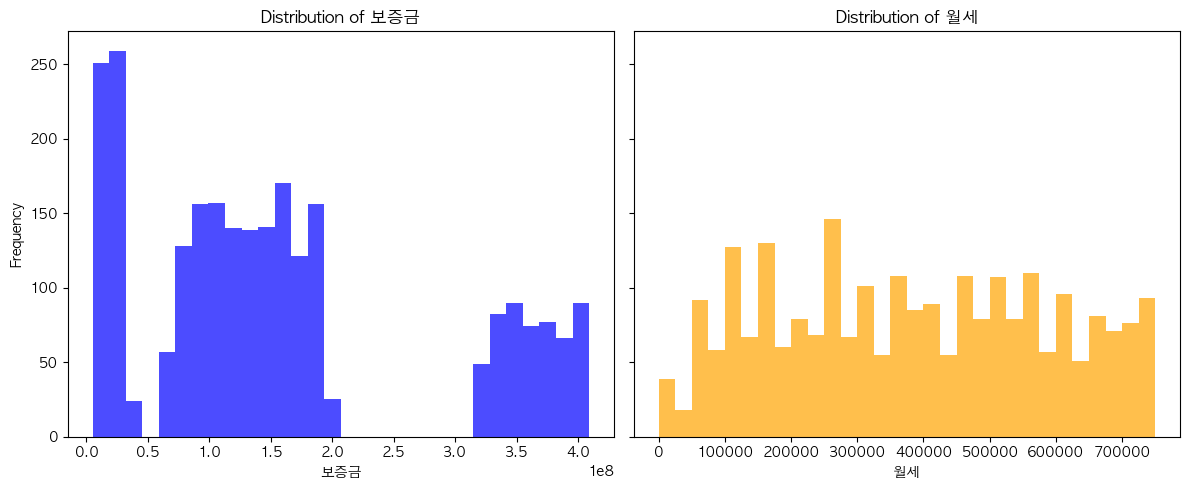

In [10]:
# 그래프 크기 설정
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# 보증금 히스토그램
axes[0].hist(data['보증금'], bins=30, alpha=0.7, color='blue')
axes[0].set_title('Distribution of 보증금')
axes[0].set_xlabel('보증금')
axes[0].set_ylabel('Frequency')

# 월세 히스토그램
axes[1].hist(data['월세'], bins=30, alpha=0.7, color='orange')
axes[1].set_title('Distribution of 월세')
axes[1].set_xlabel('월세')

# 그래프 간격 조정
plt.tight_layout()

# 그래프 표시
plt.show()

In [11]:
scaler = MinMaxScaler()
data['월세_scaled'] = scaler.fit_transform(data[['월세']])
data['보증금_scaled'] = scaler.fit_transform(data[['보증금']])

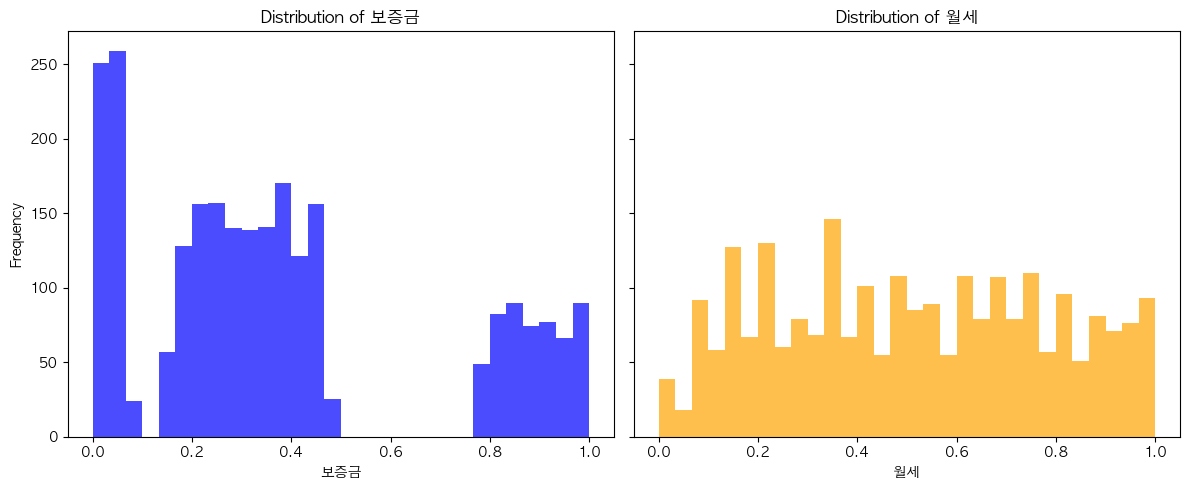

In [12]:
# 그래프 크기 설정
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# 보증금 히스토그램
axes[0].hist(data['보증금_scaled'], bins=30, alpha=0.7, color='blue')
axes[0].set_title('Distribution of 보증금')
axes[0].set_xlabel('보증금')
axes[0].set_ylabel('Frequency')

# 월세 히스토그램
axes[1].hist(data['월세_scaled'], bins=30, alpha=0.7, color='orange')
axes[1].set_title('Distribution of 월세')
axes[1].set_xlabel('월세')

# 그래프 간격 조정
plt.tight_layout()

# 그래프 표시
plt.show()

In [13]:
data.drop(columns=['월세', '보증금'],inplace=True)

In [14]:
# 모델 기반 결측값 대체 함수
def predict_missing_values(data, target_col):
    # 데이터 분리
    train_data = data[data[target_col].notnull()]
    test_data = data[data[target_col].isnull()]

    if train_data.empty or test_data.empty:
        return data  # 결측값이 없으면 그대로 반환

    # 입력 변수와 타겟 변수 나누기
    X_train = train_data.drop(columns=[target_col])
    y_train = train_data[target_col]
    X_test = test_data.drop(columns=[target_col])

    # 범주형 변수 처리
    X_train = pd.get_dummies(X_train, drop_first=True)
    X_test = pd.get_dummies(X_test, drop_first=True)

    # Ensure training and test have the same columns
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

    # 모델 학습
    model = XGBRegressor(random_state=42, n_estimators=100, max_depth=3)
    model.fit(X_train, y_train)

    # 예측값 삽입
    predicted_values = model.predict(X_test)
    data.loc[data[target_col].isnull(), target_col] = predicted_values
    return data

# 결측값이 있는 열 자동 탐지 및 처리
def fill_missing_values_with_model(data):
    missing_columns = data.columns[data.isnull().any()]
    for col in missing_columns:
        print(f"Processing column: {col}")
        data = predict_missing_values(data, col)
    return data

# 데이터프레임에 적용
data_filled = fill_missing_values_with_model(data)

# 결과 확인
print(data_filled.isnull().sum())

Processing column: 전용면적
Processing column: 해당층
Processing column: 총층
Processing column: 방수
Processing column: 욕실수
Processing column: 총주차대수
ID            0
매물확인방식        0
전용면적          0
해당층           0
총층            0
방향            0
방수            0
욕실수           0
주차가능여부        0
총주차대수         0
관리비           0
중개사무소         0
제공플랫폼         0
게재일           0
허위매물여부        0
보증금_log       0
월세_log        0
월세_scaled     0
보증금_scaled    0
dtype: int64


In [15]:
data_filled

,ID,매물확인방식,전용면적,해당층,총층,방향,방수,욕실수,주차가능여부,총주차대수,관리비,중개사무소,제공플랫폼,게재일,허위매물여부,보증금_log,월세_log,월세_scaled,보증금_scaled
0,TRAIN_0000,현장확인,20.322399,8.029914,15.0,서향,1.0,1.0,가능,40.000000,96,t93Nt6I2I0,B플랫폼,2024-10-09,0,19.813206,13.060490,0.626667,0.983911
1,TRAIN_0001,현장확인,34.122559,3.000000,4.0,남동향,2.0,1.0,불가능,4.205886,0,q39iV5J4E6,D플랫폼,2024-12-26,0,18.954246,12.206078,0.266667,0.409653
2,TRAIN_0002,전화확인,22.571646,2.000000,3.0,동향,1.0,1.0,불가능,7.579827,0,b03oE4G3F6,A플랫폼,2024-11-28,0,18.551709,12.847929,0.506667,0.269802
3,TRAIN_0003,현장확인,36.300000,3.000000,9.0,남동향,2.0,1.0,가능,13.000000,10,G52Iz8V2B9,A플랫폼,2024-11-26,0,18.912324,10.308986,0.040000,0.392327
4,TRAIN_0004,현장확인,34.256889,3.000000,3.0,동향,2.0,1.0,불가능,6.253259,0,N45gM0M7R0,B플랫폼,2024-06-25,1,19.661949,13.180634,0.706667,0.844059
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2447,TRAIN_2447,서류확인,48.950000,3.000000,3.0,남향,2.0,1.0,불가능,5.518628,0,d22DX4Y4P8,B플랫폼,2024-11-16,0,18.884415,13.217675,0.733333,0.381188
2448,TRAIN_2448,서류확인,22.510376,2.000000,4.0,남향,1.0,1.0,불가능,6.841302,2,g99sy3I3R8,A플랫폼,2024-10-06,0,18.881265,13.527830,1.000000,0.379950
2449,TRAIN_2449,전화확인,17.500000,8.000000,20.0,남서향,1.0,1.0,가능,29.000000,10,G52Iz8V2B9,B플랫폼,2024-05-15,0,19.611568,13.321216,0.813333,0.801980
2450,TRAIN_2450,현장확인,22.870000,8.000000,9.0,남동향,2.0,1.0,가능,13.771439,8,m69GM9O9B3,B플랫폼,2024-08-06,0,17.249498,12.899222,0.533333,0.064356


In [17]:
# 데이터 로드
data = data_filled.copy()

# 불필요한 열 제거
data = data.drop(columns=['ID', '중개사무소', '제공플랫폼', '게재일'])

# 범주형 변수 인코딩
categorical_columns = ['매물확인방식', '방향', '주차가능여부']
encoder = LabelEncoder()
for col in categorical_columns:
    data[col] = encoder.fit_transform(data[col])

# 특성과 타겟 변수 분리
X = data.drop(columns=['허위매물여부'])
y = data['허위매물여부']

# 학습/테스트 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 모델 학습
model = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
model.fit(X_train, y_train)

# 예측
y_pred = model.predict(X_test)

# 성능 평가
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Confusion Matrix:
 [[412  16]
 [ 48  15]]

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.96      0.93       428
           1       0.48      0.24      0.32        63

    accuracy                           0.87       491
   macro avg       0.69      0.60      0.62       491
weighted avg       0.84      0.87      0.85       491



/opt/homebrew/anaconda3/envs/test/lib/python3.12/site-packages/xgboost/core.py:158: UserWarning: [15:09:31] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


In [18]:
test_ = pd.read_csv("./data/test.csv")

In [19]:
test_

,ID,매물확인방식,보증금,월세,전용면적,해당층,총층,방향,방수,욕실수,주차가능여부,총주차대수,관리비,중개사무소,제공플랫폼,게재일
0,TEST_000,서류확인,223000000.0,530000,NaN,5.0,5.0,남향,1.0,1.0,불가능,NaN,7,Z86Th6S3K5,D플랫폼,2024-10-21
1,TEST_001,서류확인,150500000.0,590000,30.26,7.0,11.0,서향,1.0,1.0,불가능,16.0,11,G52Iz8V2B9,D플랫폼,2023-09-02
2,TEST_002,현장확인,47000000.0,200000,41.50,2.0,3.0,남서향,2.0,1.0,불가능,NaN,0,N45gM0M7R0,B플랫폼,2024-04-03
3,TEST_003,서류확인,133000000.0,250000,31.35,5.0,6.0,남향,2.0,1.0,가능,NaN,5,C41wx1K6U9,B플랫폼,2024-09-19
4,TEST_004,현장확인,108000000.0,380000,23.14,2.0,3.0,남향,1.0,1.0,불가능,NaN,0,Z68ZJ6F6L4,A플랫폼,2024-11-10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
608,TEST_608,현장확인,152500000.0,340000,30.83,4.0,6.0,남동향,1.0,1.0,가능,1.0,2,j90UQ8N6M3,A플랫폼,2024-09-24
609,TEST_609,전화확인,226500000.0,750000,29.88,NaN,10.0,남서향,2.0,1.0,가능,34.0,7,r82ax9M3U3,B플랫폼,2024-09-04
610,TEST_610,현장확인,169500000.0,500000,30.73,5.0,6.0,남향,1.0,1.0,불가능,33.0,6,G52Iz8V2B9,F플랫폼,2024-04-20
611,TEST_611,현장확인,180000000.0,340000,17.50,3.0,6.0,남동향,1.0,1.0,가능,2.0,8,J52gJ2E4T6,C플랫폼,2024-11-17


In [ ]:
# 필요 없는 열 제거
test_data_cleaned = test_.drop(columns=['중개사무소', '제공플랫폼', '게재일'])

# 범주형 변수 인코딩 (훈련 데이터 기준으로 동일한 인코딩 수행)
for col in categorical_columns:
    if col in test_data_cleaned.columns:
        test_data_cleaned[col] = encoder.transform(test_data_cleaned[col])

# 결측값 처리 (훈련 데이터와 동일한 방식)
test_data_cleaned.fillna(0, inplace=True)

# 예측 수행
test_predictions = model.predict(test_data_cleaned.drop(columns=['ID']))

# 제출 파일 생성
submission = test_data[['ID']].copy()
submission['허위매물여부'] = test_predictions

# CSV로 저장
submission.to_csv('submission.csv', index=False)

print(submission)

In [25]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from xgboost import XGBRegressor

# 데이터 로드
data = pd.read_csv("./data/train.csv")
test_data = pd.read_csv("./data/test.csv")

# MinMaxScaler 초기화 및 스케일링 적용 함수
scalers = {}
def apply_scaling(data, columns):
    for col in columns:
        scaler = MinMaxScaler()
        data[col + '_scaled'] = scaler.fit_transform(data[[col]])
        scalers[col] = scaler  # 스케일러 저장
    return data

# 훈련 데이터에 스케일링 적용
data = apply_scaling(data, ['월세', '보증금'])

# 모델 기반 결측값 대체 함수
def predict_missing_values(data, target_col):
    # 데이터 분리
    train_data = data[data[target_col].notnull()]
    test_data = data[data[target_col].isnull()]

    if train_data.empty or test_data.empty:
        return data  # 결측값이 없으면 그대로 반환

    # 입력 변수와 타겟 변수 나누기
    X_train = train_data.drop(columns=[target_col])
    y_train = train_data[target_col]
    X_test = test_data.drop(columns=[target_col])

    # 범주형 변수 처리
    X_train = pd.get_dummies(X_train, drop_first=True)
    X_test = pd.get_dummies(X_test, drop_first=True)

    # Ensure training and test have the same columns
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

    # 모델 학습
    model = XGBRegressor(random_state=42, n_estimators=100, max_depth=3)
    model.fit(X_train, y_train)

    # 예측값 삽입
    predicted_values = model.predict(X_test)
    data.loc[data[target_col].isnull(), target_col] = predicted_values
    return data

# 결측값이 있는 열 자동 탐지 및 처리
def fill_missing_values_with_model(data):
    missing_columns = data.columns[data.isnull().any()]
    for col in missing_columns:
        print(f"Processing column: {col}")
        data = predict_missing_values(data, col)
    return data

# 훈련 데이터 결측값 처리
data_filled = fill_missing_values_with_model(data)

# 테스트 데이터 처리
# 스케일링 적용
def apply_test_scaling(test_data, scalers):
    for col, scaler in scalers.items():
        test_data[col + '_scaled'] = scaler.transform(test_data[[col]])
    return test_data
test_data = apply_test_scaling(test_data, scalers)

# 테스트 데이터 결측값 처리
def fill_test_missing_values_with_model(test_data, train_data):
    train_columns = train_data.select_dtypes(include=[np.number]).columns
    test_data = pd.get_dummies(test_data, drop_first=True)
    test_data = test_data.reindex(columns=train_columns, fill_value=0)

    for col in train_data.columns[train_data.isnull().any()]:
        if col in test_data.columns:
            train_data_col = train_data[~train_data[col].isnull()]
            model = XGBRegressor(random_state=42, n_estimators=100, max_depth=3)
            model.fit(train_data_col.drop(columns=[col]), train_data_col[col])
            test_data.loc[test_data[col].isnull(), col] = model.predict(test_data[test_data[col].isnull()].drop(columns=[col]))
    return test_data

test_data_filled = fill_test_missing_values_with_model(test_data, data_filled)

# 최종 예측
data_numeric = data_filled.select_dtypes(include=[np.number])
X_test = test_data_filled.select_dtypes(include=[np.number]).drop(columns=['허위매물여부'], errors='ignore')
y_pred = XGBRegressor(random_state=42, n_estimators=100, max_depth=3).fit(
    data_numeric.drop(columns=['허위매물여부']), data_numeric['허위매물여부']
).predict(X_test)

# 제출 파일 생성
submission = test_data[['ID']].copy()
submission['허위매물여부'] = np.round(y_pred).astype(int)
submission.to_csv('submission.csv', index=False)

print(submission)


Processing column: 전용면적
Processing column: 해당층
Processing column: 총층
Processing column: 방수
Processing column: 욕실수
Processing column: 총주차대수
           ID  허위매물여부
0    TEST_000       0
1    TEST_001       0
2    TEST_002       0
3    TEST_003       0
4    TEST_004       0
..        ...     ...
608  TEST_608       0
609  TEST_609       0
610  TEST_610       0
611  TEST_611       0
612  TEST_612       0

[613 rows x 2 columns]
